# Segmentation-Aware Early Traffic Accident Anticipation from Dashcam Video
**Deep Learning mini-project: full walkthrough in one notebook**

**Question:** does road context from semantic segmentation help a recurrent model warn *earlier* and *more accurately* before a dashcam crash?

| Section | What it shows |
|---|---|
| 1 | Setup and data (CCD, DoTA) |
| 2 | Pipeline: Stage A perception features, Stage B model |
| 3 | Model, loss, metrics, training loop (with a small runnable training demo) |
| 4 | Experiment design |
| 5 | **Demo cases:** 2 earlier warnings, 1 false alarm, 1 miss (video + storyboard) |
| 6 | **Results:** baselines, main model, ablations, cross-dataset, early vs late, errors, benchmark audit |

> Stage A (YOLO11 + SegFormer + DINOv2 on ~6,000 videos) took ~3.7 h on 2×T4 GPUs, and the 385 Stage B runs were trained on Kaggle. So this notebook **shows the code** and **loads the saved outputs** (`results/`) instead of re-running them. The cells that run live here are the data statistics, the context-feature demo, and a small toy training run.

## 1. Setup and data

In [1]:
import os, re, json, glob, time
import torch, torch.nn as nn, torch.nn.functional as F   # torch first (importing pandas before torch crashes on this Windows setup)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, Video, display

# Auto-detect project root across local environments and Kaggle (/kaggle/input/...)
ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, 'results')):
    if os.path.isdir('/kaggle/input'):
        for r, dirs, _ in os.walk('/kaggle/input'):
            if 'results' in dirs and 'configs' in dirs:
                ROOT = r
                break
            elif 'results' in dirs:
                ROOT = r
    if not os.path.isdir(os.path.join(ROOT, 'results')):
        ROOT = os.path.dirname(ROOT)

RES = os.path.join(ROOT, 'results'); TAB = os.path.join(RES, 'tables')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
print('project root:', ROOT)


project root: D:\Programs\LY\DL\miniproj


### Datasets
* **CCD** (Car Crash Dataset): 1,500 crash clips (YouTube) + 3,000 normal clips (BDD100K), 50 frames at 10 fps. Time of accident `toa` = first frame labelled 1.
* **DoTA** (as prepared by STAGNet): 745 pre-accident clips + 745 negative clips (post-accident windows), 50 frames at 10 fps, 1280×720.
* An alarm is useful only if it comes **before** `toa`, so every metric looks at the frames before `toa`.

CCD crash clips: 1500, distinct YouTube sources: 133
time of accident: frames 30..49  ->  at least 3 s of normal driving before every crash


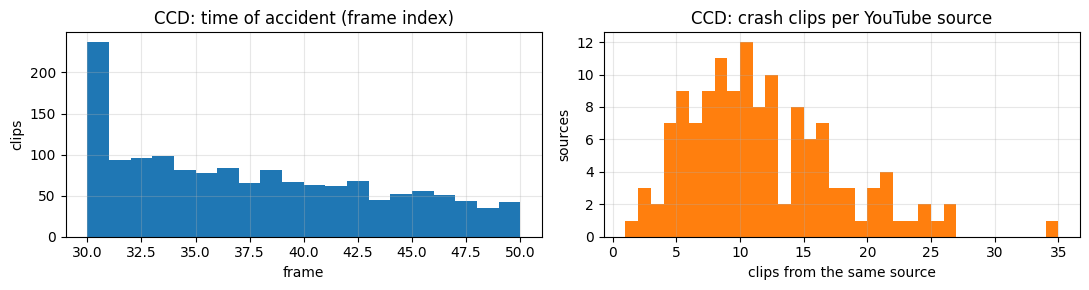

In [2]:
# CCD labels straight from the annotation file: per-frame 0/1 list, accident frame = first 1, YouTube source id
toa, src = [], []
for line in open(os.path.join(ROOT, "data/ccd_meta/Crash-1500.txt")):
    m = re.match(r"(\d+),\[(.*?)\],(\d+),(\d+),", line.strip())
    toa.append([int(x) for x in m.group(2).split(",")].index(1)); src.append(m.group(4))
toa = np.array(toa)
print(f"CCD crash clips: {len(toa)}, distinct YouTube sources: {len(set(src))}")
print(f"time of accident: frames {toa.min()}..{toa.max()}  ->  at least {toa.min()/10:.0f} s of normal driving before every crash")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(toa, bins=range(30, 51), color="C0"); ax[0].set(title="CCD: time of accident (frame index)", xlabel="frame", ylabel="clips")
cnt = pd.Series(src).value_counts()
ax[1].hist(cnt.values, bins=range(1, cnt.max() + 2), color="C1"); ax[1].set(title="CCD: crash clips per YouTube source", xlabel="clips from the same source", ylabel="sources")
plt.tight_layout(); plt.show()

## 2. Pipeline

```
 dashcam video (50 frames, 10 fps)
   │
   ├─ STAGE A (run once, cached to .npz per video)
   │     YOLO11m + ByteTrack ─► boxes, class, track id         ─► geometry + motion (16-d per object)
   │     DINOv2-small        ─► frame embedding (384) and per-object appearance (384)
   │     SegFormer-B2        ─► road / sidewalk map ─► 9 segmentation-context features per object
   │
   └─ STAGE B (trained many times, fast)
         object features ─► encoder ─► graph attention over objects ─► attention pooling ─► LSTM ─► P(accident) per frame
         loss: exponential anticipation loss      metrics: AP, mTTA, TTA@R80
```
**Models compared** (all are the same network with parts switched on or off):

| name | object features | interaction |
|---|---|---|
| `frame_lstm` | none (whole-frame embedding only) | – |
| `det_lstm` | appearance + geometry | none |
| `det_graph` | appearance + geometry | graph attention |
| **`main`** | appearance + geometry + **segmentation context** | graph attention |

### 2.1 Stage A: segmentation-context features (the project's idea)
For each detected object we ask where it is relative to the road: how much of its box is on the road, whether its ground-contact point is on road or sidewalk, signed distance to the road edge, and offset from the ego lane. Nine features per object. The code below is the real function from `src/features/extract.py`, run here on a toy label map (Stage A itself needs GPUs and the raw videos).

In [3]:
import cv2
ROAD, SIDEWALK = 0, 1       # Cityscapes label ids
CTX_FEATURES = ["road_frac_box", "drivable_overlap_bottom", "foot_on_road", "foot_on_sidewalk",
                "foot_road_signed_dist", "ego_lane_offset", "abs_ego_lane_offset", "bottom_y", "height_frac"]

def ego_lane_x(lab):
    """x (fraction of width) of the road centre in a band at 65-85% of image height (above the hood)."""
    h, w = lab.shape
    band = lab[int(h*.65):int(h*.85), int(w*.25):int(w*.75)] == ROAD
    return 0.5 if band.sum() < 10 else float((np.nonzero(band)[1] + int(w*.25)).mean() / w)

def context(lab, d_in, d_out, boxes, W, H, ego_x):
    """Segmentation-context features for boxes (n,4) in pixels; lab is the (h,w) label map."""
    h, w = lab.shape; sx, sy = w / W, h / H
    out = np.zeros((len(boxes), len(CTX_FEATURES)), np.float32)
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        a, b = int(np.clip(x1*sx, 0, w-1)), int(np.clip(np.ceil(x2*sx), 1, w))
        c, d = int(np.clip(y1*sy, 0, h-1)), int(np.clip(np.ceil(y2*sy), 1, h))
        box = lab[c:max(d, c+1), a:max(b, a+1)]
        gap = max(1, int(min(0.03*h, 0.15*(d-c))))
        bottom = lab[max(d - max((d-c)//10, 1), 0):min(d+gap, h), a:max(b, a+1)]       # strip at ground contact
        fx, fy = int(np.clip((x1+x2)/2*sx, 0, w-1)), int(np.clip(y2*sy + gap, 0, h-1))  # point just below the box
        win = lab[max(fy-2, 0):fy+3, max(fx-2, 0):fx+3]
        on_road = float(np.mean(win == ROAD) > 0.3)
        dist = (d_in[fy, fx] if on_road else -d_out[fy, fx]) / h                         # + inside road, - outside
        off = (x1+x2)/2/W - ego_x
        out[i] = [np.mean(box == ROAD), np.mean(bottom == ROAD), on_road, float(np.mean(win == SIDEWALK) > 0.3),
                  np.clip(dist, -1, 1), off, abs(off), y2/H, (y2-y1)/H]
    return out

# toy scene 128x72: road in the middle, sidewalk on the right, one car on the road and one on the sidewalk
lab = np.full((72, 128), 2, np.uint8); lab[30:, 30:90] = ROAD; lab[30:, 90:110] = SIDEWALK
W, H = 1280, 720
boxes = np.array([[500, 450, 640, 560], [920, 430, 1000, 520]], float)     # pixels at 1280x720
d_in  = cv2.distanceTransform((lab == ROAD).astype(np.uint8), cv2.DIST_L2, 3)
d_out = cv2.distanceTransform((lab != ROAD).astype(np.uint8), cv2.DIST_L2, 3)
feat = context(lab, d_in, d_out, boxes, W, H, ego_lane_x(lab))
display(pd.DataFrame(feat, columns=CTX_FEATURES, index=["car on road", "car on sidewalk"]).round(2))

,road_frac_box,drivable_overlap_bottom,foot_on_road,foot_on_sidewalk,foot_road_signed_dist,ego_lane_offset,abs_ego_lane_offset,bottom_y,height_frac
car on road,1.0,1.0,1.0,0.0,0.37,-0.03,0.03,0.78,0.15
car on sidewalk,0.0,0.0,0.0,1.0,-0.09,0.28,0.28,0.72,0.12


### 2.2 Stage B inputs
Per frame: up to 19 objects (as in UString / STAGNet), each with
* `app` (384) DINOv2 appearance, `geo` (16) class, normalised box, confidence, velocity, scale change, track age (**detection only, no segmentation**), `seg` (9) the context features above, and `mask` marking real detections;
* plus a whole-frame DINOv2 embedding `frame` (384).

## 3. Model, loss, metrics, training
### 3.1 Model
`RiskNet` is one class that builds baselines 2 and 3, the main model and all ablations (choose feature groups, interaction on/off, frame embedding on/off, LSTM/GRU). `FrameRNN` is the frame-only baseline.
Per frame: encode object features, **graph attention** over the objects (logits biased by `-distance/τ`, so near objects interact more), **attention pooling** conditioned on the previous hidden state (these weights are shown as box colour in the demo), then an **LSTM cell** → P(accident).

In [4]:
DIMS = dict(app=384, geo=16, seg=9, frame=384)

class FrameRNN(nn.Module):
    """Baseline 1: whole-frame embedding -> LSTM -> risk."""
    def __init__(self, hidden=256, rnn="lstm", dropout=0.3, **_):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(DIMS["frame"], hidden), nn.ReLU(), nn.Dropout(dropout))
        self.rnn = (nn.LSTM if rnn == "lstm" else nn.GRU)(hidden, hidden, batch_first=True)
        self.out = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 2))
    def forward(self, b):
        h, _ = self.rnn(self.enc(b["frame"]))
        return dict(logits=self.out(h), attn=None)

class RiskNet(nn.Module):
    def __init__(self, obj_groups=("app", "geo", "seg"), interaction="graph", use_frame=True, rnn="lstm",
                 hidden=256, heads=4, tau=0.2, dropout=0.3):
        super().__init__()
        self.groups, self.interaction, self.use_frame, self.rnn_type, self.tau = list(obj_groups), interaction, use_frame, rnn, tau
        self.enc = nn.ModuleDict({g: nn.Sequential(nn.Linear(DIMS[g], hidden), nn.ReLU()) for g in self.groups})
        self.obj_proj = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * len(self.groups), hidden), nn.ReLU())
        if interaction == "graph":
            self.heads = heads
            self.qkv = nn.Linear(hidden, 3 * hidden); self.gat_out = nn.Linear(hidden, hidden); self.norm = nn.LayerNorm(hidden)
        if use_frame:
            self.frame_enc = nn.Sequential(nn.Linear(DIMS["frame"], hidden), nn.ReLU(), nn.Dropout(dropout))
        self.att_h, self.att_o, self.att_w = nn.Linear(hidden, hidden), nn.Linear(hidden, hidden), nn.Linear(hidden, 1)
        cell_in = hidden * (2 if use_frame else 1)
        self.cell = nn.LSTMCell(cell_in, hidden) if rnn == "lstm" else nn.GRUCell(cell_in, hidden)
        self.out = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 2))
        self.hidden = hidden

    def interact(self, x, mask, centers):
        """One graph-attention layer over the objects of a frame, attention biased by -distance/tau."""
        BT, N, H = x.shape
        q, k, v = self.qkv(x).view(BT, N, 3, self.heads, H // self.heads).unbind(2)
        logits = torch.einsum("bnhd,bmhd->bhnm", q, k) / (H // self.heads) ** 0.5
        logits = logits - (torch.cdist(centers, centers) / self.tau).unsqueeze(1)
        logits = logits.masked_fill(~mask[:, None, None, :], -1e4)
        a = torch.softmax(logits, -1)
        y = torch.einsum("bhnm,bmhd->bnhd", a, v).reshape(BT, N, H)
        return self.norm(x + self.gat_out(y))

    def forward(self, b):
        B, T, N = b["mask"].shape; mask = b["mask"]
        x = self.obj_proj(torch.cat([self.enc[g](b[g]) for g in self.groups], -1))        # (B,T,N,H)
        if self.interaction == "graph":
            geo = b["geo_raw"]
            centers = torch.stack([(geo[..., 6] + geo[..., 8]) / 2, (geo[..., 7] + geo[..., 9]) / 2], -1)
            x = self.interact(x.reshape(B*T, N, -1), mask.reshape(B*T, N), centers.reshape(B*T, N, 2)).view(B, T, N, -1)
        f = self.frame_enc(b["frame"]) if self.use_frame else None
        h = x.new_zeros(B, self.hidden); c = x.new_zeros(B, self.hidden)
        o_proj, any_obj = self.att_o(x), mask.any(-1)
        logits, attns = [], []
        for t in range(T):
            e = self.att_w(torch.tanh(self.att_h(h)[:, None] + o_proj[:, t])).squeeze(-1)   # which object matters now?
            a = torch.softmax(e.masked_fill(~mask[:, t], -1e4), -1) * any_obj[:, t, None]
            pooled = (a.unsqueeze(-1) * x[:, t]).sum(1)
            inp = torch.cat([pooled, f[:, t]], -1) if self.use_frame else pooled
            if self.rnn_type == "lstm": h, c = self.cell(inp, (h, c))
            else: h = self.cell(inp, h)
            logits.append(self.out(h)); attns.append(a)
        return dict(logits=torch.stack(logits, 1), attn=torch.stack(attns, 1))

def build(spec):
    if spec["model"] == "frame":
        return FrameRNN(rnn=spec.get("rnn", "lstm"))
    return RiskNet(obj_groups=spec.get("groups", ("app", "geo", "seg")), interaction=spec.get("interaction", "graph"),
                   use_frame=spec.get("use_frame", True), rnn=spec.get("rnn", "lstm"))

for name, spec in {"frame_lstm": dict(model="frame"),
                   "det_lstm": dict(model="risknet", groups=["app", "geo"], interaction="none"),
                   "det_graph": dict(model="risknet", groups=["app", "geo"], interaction="graph"),
                   "main": dict(model="risknet", groups=["app", "geo", "seg"], interaction="graph")}.items():
    print(f"{name:11s} parameters: {sum(p.numel() for p in build(spec).parameters()):,}")

frame_lstm  parameters: 625,410
det_lstm    parameters: 1,253,635
det_graph   parameters: 1,517,315
main        parameters: 1,585,411


### 3.2 Exponential anticipation loss
For an accident video, a frame far before the accident should be penalised less than one right before it, otherwise the model cannot learn to be *early without being wrong*. Positive frame `t` is weighted by `exp(-max(0, (toa - t - 1)/fps))`; negative videos use plain cross-entropy (same as DSA-RNN and UString).

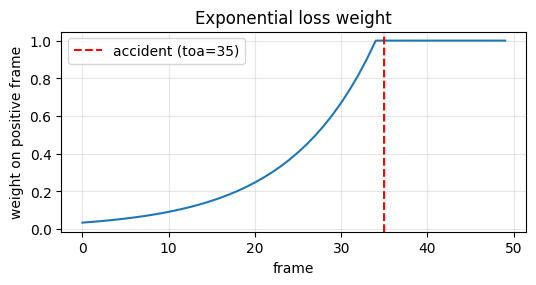

In [5]:
def exp_loss(logits, y, toa, fps=10.0):
    """logits (B,T,2), y (B,), toa (B,)"""
    B, T, _ = logits.shape
    t = torch.arange(T, device=logits.device)[None].float()
    ce_pos = F.cross_entropy(logits.reshape(-1, 2), torch.ones(B*T, dtype=torch.long), reduction="none").view(B, T)
    ce_neg = F.cross_entropy(logits.reshape(-1, 2), torch.zeros(B*T, dtype=torch.long), reduction="none").view(B, T)
    w = torch.exp(-torch.clamp((toa[:, None].float() - t - 1) / fps, min=0))
    yf = y[:, None].float()
    return (yf * w * ce_pos + (1 - yf) * ce_neg).mean()

t = np.arange(50); w = np.exp(-np.maximum(0, (35 - t - 1) / 10))
plt.figure(figsize=(6, 2.6)); plt.plot(t, w); plt.axvline(35, c="r", ls="--", label="accident (toa=35)")
plt.xlabel("frame"); plt.ylabel("weight on positive frame"); plt.legend(); plt.title("Exponential loss weight"); plt.show()

### 3.3 Metrics (same definitions as UString / STAGNet)
* **AP**: average precision over alarm thresholds, at video level. A video is "alarmed" if *any* frame before `toa` reaches the threshold.
* **mTTA**: mean time-to-accident of correctly alarmed videos, averaged over thresholds. (Field definition: relative lead time × 5 s clip length, so it is not literally seconds before the crash.)
* **TTA@R80**: time-to-accident at 80% recall.

In [6]:
def evaluation(all_pred, all_labels, time_of_accidents, fps=10.0):
    """Reproduction of UString's evaluation(). all_pred (N,T) probabilities; returns AP, mTTA, TTA@R80."""
    preds = [p[:int(t)] if y > 0 else p for p, y, t in zip(all_pred, all_labels, time_of_accidents)]
    min_pred = min(np.min(p) for p in preds); n_frames = sum(len(p) for p in preds)
    total_seconds = all_pred.shape[1] / fps
    Precision, Recall, Time = np.zeros(n_frames), np.zeros(n_frames), np.zeros(n_frames); cnt = 0
    for Th in np.arange(max(min_pred, 0), 1.0, 0.001):
        Tp = Tp_Fp = time = counter = 0.0
        for i in range(len(preds)):
            tp = np.where(preds[i] * all_labels[i] >= Th)
            Tp += float(len(tp[0]) > 0)
            if len(tp[0]) > 0:
                time += tp[0][0] / float(time_of_accidents[i]); counter += 1
            Tp_Fp += float(len(np.where(preds[i] >= Th)[0]) > 0)
        if Tp_Fp == 0: continue
        Precision[cnt] = Tp / Tp_Fp
        if np.sum(all_labels) == 0: continue
        Recall[cnt] = Tp / np.sum(all_labels)
        if counter == 0: continue
        Time[cnt] = 1 - time / counter; cnt += 1
    idx = np.argsort(Recall); Precision, Recall, Time = Precision[idx], Recall[idx], Time[idx]
    _, rep = np.unique(Recall, return_index=1); rep = rep[1:]
    new_T, new_P = np.zeros(len(rep)), np.zeros(len(rep))
    for i in range(len(rep) - 1):
        new_T[i] = np.max(Time[rep[i]:rep[i+1]]); new_P[i] = np.max(Precision[rep[i]:rep[i+1]])
    new_T[-1], new_P[-1], new_R = Time[rep[-1]], Precision[rep[-1]], Recall[rep]
    AP = new_P[0] * new_R[0] if new_R[0] != 0 else 0.0
    for i in range(1, len(new_P)):
        AP += (new_P[i-1] + new_P[i]) * (new_R[i] - new_R[i-1]) / 2
    mTTA = np.mean(new_T) * total_seconds
    r80 = new_T[np.argsort(new_R)][np.argmin(np.abs(np.sort(new_R) - 0.8))] * total_seconds
    return float(AP), float(mTTA), float(r80)

# sanity check on synthetic risk curves: 30 accident videos (toa = frame 40) + 30 normal videos
rs = np.random.default_rng(0); T_, N_ = 50, 60
y_ = np.r_[np.ones(30), np.zeros(30)]; toa_ = np.r_[np.full(30, 40), np.full(30, 50)]
def curves(ramp_start):                                   # noise 0.05-0.35, accident videos ramp up by +0.6 from ramp_start
    pr = rs.uniform(0.05, 0.35, (N_, T_)); pr[:30] += 0.6 * np.clip((np.arange(T_) - ramp_start) / 8, 0, 1)
    return np.clip(pr, 0, 1)
for name, pr in [("early warning (ramp at frame 10)", curves(10)), ("late warning (ramp at frame 32)", curves(32)),
                 ("random scores", rs.uniform(0, 1, (N_, T_)))]:
    print(f"{name:34s} AP / mTTA / TTA@R80 =", [round(v, 2) for v in evaluation(pr, y_, toa_)])

early warning (ramp at frame 10)   AP / mTTA / TTA@R80 = [0.99, 1.86, 1.84]


late warning (ramp at frame 32)    AP / mTTA / TTA@R80 = [0.99, 0.34, 0.21]


random scores                      AP / mTTA / TTA@R80 = [0.55, 2.9, 3.2]


### 3.4 Training loop
Per (experiment, split, seed): AdamW (lr 3e-4, weight decay 1e-4), batch 32 videos, up to 40 epochs, gradient clipping, **early stopping on validation AP** (patience 8; the validation set is 10% of the training videos, grouped like the split), then restore the best checkpoint and evaluate on the held-out fold. Features are z-normalised with training statistics.
The real runner is `src/train/run.py` (it also does data loading, resume and logging). The core is below.

In [7]:
def predict(model, data, idx, bs=64):
    model.eval(); P = []
    with torch.no_grad():
        for i in range(0, len(idx), bs):
            b = {k: v[idx[i:i+bs]] for k, v in data.items()}
            P.append(torch.softmax(model(b)["logits"], -1)[..., 1].numpy())
    return np.concatenate(P)

def train_eval(data, y, toa, fit_idx, val_idx, test_idx, spec, epochs=40, patience=8, lr=3e-4, bs=32, seed=0, verbose=True):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = build(spec)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); perm = rng.permutation(fit_idx); losses = []
        for i in range(0, len(perm), bs):
            j = np.sort(perm[i:i+bs])
            out = model({k: v[j] for k, v in data.items()})
            loss = exp_loss(out["logits"], torch.from_numpy(y[j]), torch.from_numpy(toa[j]))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); losses.append(loss.item())
        val_ap = evaluation(predict(model, data, val_idx), y[val_idx], toa[val_idx])[0]
        if verbose: print(f"epoch {ep+1:2d}  train loss {np.mean(losses):.4f}  val AP {val_ap:.3f}")
        if val_ap > best + 1e-4:
            best, bad = val_ap, 0; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)                                    # best checkpoint on validation AP
    p = predict(model, data, test_idx)
    return model, p, evaluation(p, y[test_idx], toa[test_idx])

#### Runnable demo of the training and evaluation loop (toy data)
The real features are on Kaggle, so this cell trains on **small random tensors with a planted signal** (accident videos get a drifting feature before `toa`) only to show the loop, early stopping and the metrics running end to end. The numbers here mean nothing for the project; the real numbers are in Section 6.

In [8]:
torch.manual_seed(0); rng = np.random.default_rng(0)
B, T, N = 200, 50, 19
y = np.r_[np.ones(B // 2), np.zeros(B // 2)].astype(int)
toa = np.where(y == 1, rng.integers(30, 50, B), 50)
data = dict(app=torch.randn(B, T, N, 384), geo=torch.rand(B, T, N, 16), seg=torch.randn(B, T, N, 9),
            frame=torch.randn(B, T, 384), mask=torch.rand(B, T, N) < 0.5)
data["geo_raw"] = data["geo"].clone()
for i in np.where(y == 1)[0]:                                            # planted signal: the frame embedding drifts before toa
    ramp = torch.clamp((torch.arange(T) - (toa[i] - 20)).float() / 20, 0, 1)
    data["frame"][i, :, :32] += 2.0 * ramp[:, None]
perm = rng.permutation(B); fit_idx, val_idx, test_idx = perm[:120], perm[120:160], perm[160:]
spec = dict(model="risknet", groups=["app", "geo", "seg"], interaction="graph")
t0 = time.time()
model, p, (AP, mTTA, R80) = train_eval(data, y, toa, fit_idx, val_idx, test_idx, spec, epochs=8, patience=4)
print(f"\ntoy test result: AP {AP:.3f}  mTTA {mTTA:.2f}  TTA@R80 {R80:.2f}   ({time.time()-t0:.0f}s on CPU)")

epoch  1  train loss 0.4337  val AP 0.676


epoch  2  train loss 0.3832  val AP 0.990


epoch  3  train loss 0.3152  val AP 0.990


epoch  4  train loss 0.2407  val AP 0.990


epoch  5  train loss 0.1687  val AP 0.990


epoch  6  train loss 0.1334  val AP 0.990



toy test result: AP 0.988  mTTA 0.52  TTA@R80 0.36   (99s on CPU)


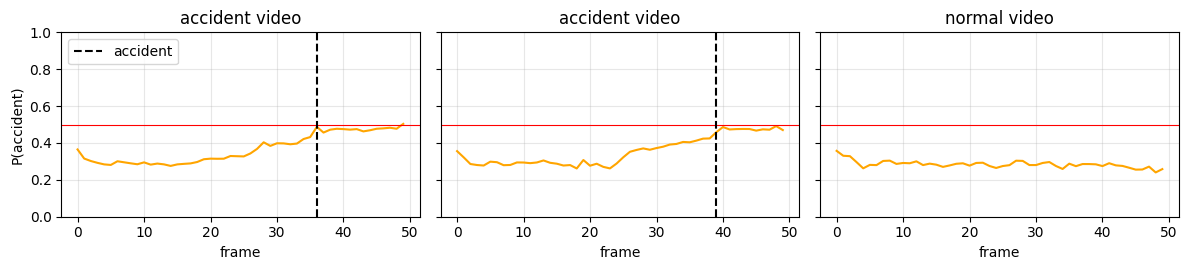

In [9]:
# risk curves of the toy model on a few held-out videos
ty = y[test_idx]; pos, neg = np.where(ty == 1)[0], np.where(ty == 0)[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for a, k in zip(ax, [pos[0], pos[1], neg[0]]):
    a.plot(p[k], c="orange"); a.axhline(.5, c="r", lw=.8)
    if ty[k]: a.axvline(toa[test_idx][k], c="k", ls="--", label="accident")
    a.set(title=("accident video" if ty[k] else "normal video"), xlabel="frame", ylim=(0, 1))
ax[0].set_ylabel("P(accident)"); ax[0].legend(); plt.tight_layout(); plt.show()

## 4. Experiment design (`configs/experiments.yaml`)
Every row in the results comes from a run defined here: **3 seeds × 5 folds**, 385 runs in total.
* **Comparable splits:** CCD official split; DoTA STAGNet folds (grouped by clip), the protocols of the literature.
* **Clean splits:** 5-fold grouped by **YouTube source**, so no source appears in both training and test.
* **Ablations (DoTA clean only):** remove interaction, appearance, geometry, frame embedding; GRU instead of LSTM; geometry only; geometry + segmentation.
* **Cross-dataset:** train on all of CCD and test on all of DoTA, and the reverse.
* **Early vs late:** rule fixed beforehand: alarm at P ≥ 0.5, compare `main` and `det_graph` per video.

In [10]:
import yaml
cfg = yaml.safe_load(open(os.path.join(ROOT, "configs/experiments.yaml")))
rows = [dict(name=e["name"], model=e["model"], feature_groups="+".join(e.get("groups", ["frame only"])),
             interaction=e.get("interaction", "-"), frame_embedding=e.get("use_frame", True),
             rnn=e.get("rnn", "lstm"), runs_on=", ".join(e["run_on"])) for e in cfg["experiments"]]
display(pd.DataFrame(rows).set_index("name"))
print("training:", cfg["train"], "| seeds:", cfg["seeds"])

,model,feature_groups,interaction,frame_embedding,rnn,runs_on
name,,,,,,
frame_lstm,frame,frame only,-,True,lstm,"comparable, clean"
det_lstm,risknet,app+geo,none,True,lstm,"comparable, clean"
det_graph,risknet,app+geo,graph,True,lstm,"comparable, clean"
main,risknet,app+geo+seg,graph,True,lstm,"comparable, clean"
main_no_interaction,risknet,app+geo+seg,none,True,lstm,ablation
main_no_app,risknet,geo+seg,graph,True,lstm,ablation
main_no_geo,risknet,app+seg,graph,True,lstm,ablation
main_no_frame,risknet,app+geo+seg,graph,False,lstm,ablation
main_gru,risknet,app+geo+seg,graph,True,gru,ablation


training: {'epochs': 40, 'patience': 8, 'batch_size': 32, 'lr': 0.0003, 'weight_decay': 0.0001, 'val_fraction': 0.1} | seeds: [0, 1, 2]


## 5. Demo cases
Four clips chosen by a rule fixed in `configs/experiments.yaml` before looking at results: the **two largest earlier-warning margins** of `main` over `det_graph` (DoTA), the **most confident false alarm** and the **clearest miss** of `main` (these two came from CCD).

Each video shows **left: detection-only model (`det_graph`)** and **right: main model (+ road context)**: SegFormer road mask in purple, boxes redder where the pooling attention is higher, and the risk curve with the 0.5 threshold and the accident marker. The storyboard beneath each video shows the same clip as stills.

In [11]:
DEMO = os.path.join(RES, "demo")
info = {d["tag"]: d for d in json.load(open(os.path.join(DEMO, "demo_info.json")))}
def show_case(prefix, title, note):
    tag = next(t for t in info if t.startswith(prefix))
    d = info[tag]
    display(Markdown(f"### {title}\n`{tag}`  \n**main model:** {d['main']}  \n**detection-only baseline:** {d['baseline']}  \n{note}"))
    display(Video(os.path.join(DEMO, tag + ".mp4"), embed=True, width=960, html_attributes="controls loop muted"))
    display(Markdown("*Storyboard (same clip, stills):*"))
    display(Image(os.path.join(DEMO, tag + "_storyboard.png"), width=960))

#### 5.1 Earlier warning (1 of 2)

### Earlier warning, DoTA clip UOjQsfDXjO0_004067
`earlier_warning_dota_pos_UOjQsfDXjO0_004067`  
**main model:** warned 3.5 s before the accident  
**detection-only baseline:** warned 0.5 s before the accident  
The main model's risk rises above 0.5 early in the clip; the baseline only crosses it just before the crash.

*Storyboard (same clip, stills):*

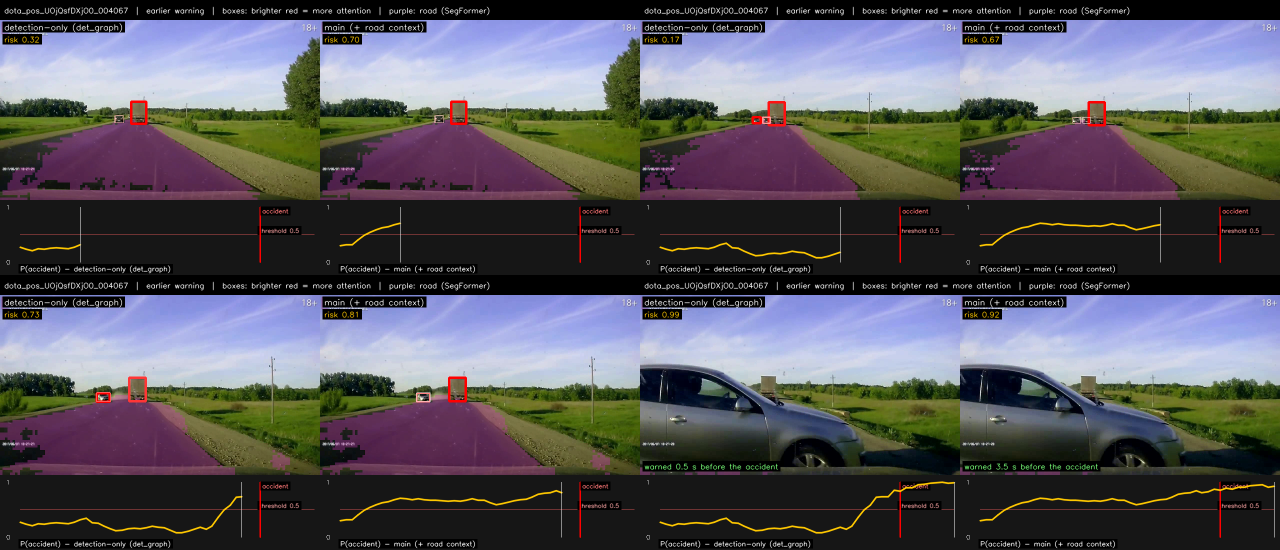

In [12]:
show_case("earlier_warning_dota_pos_UOjQsfDXjO0", "Earlier warning, DoTA clip UOjQsfDXjO0_004067", "The main model's risk rises above 0.5 early in the clip; the baseline only crosses it just before the crash.")

#### 5.2 Earlier warning (2 of 2)

### Earlier warning, DoTA clip gDjeTHGWX9c_003096
`earlier_warning_dota_pos_gDjeTHGWX9c_003096`  
**main model:** warned 2.7 s before the accident  
**detection-only baseline:** warned 0.6 s before the accident  
Same pattern: the main model alarms about 2 s before the baseline does.

*Storyboard (same clip, stills):*

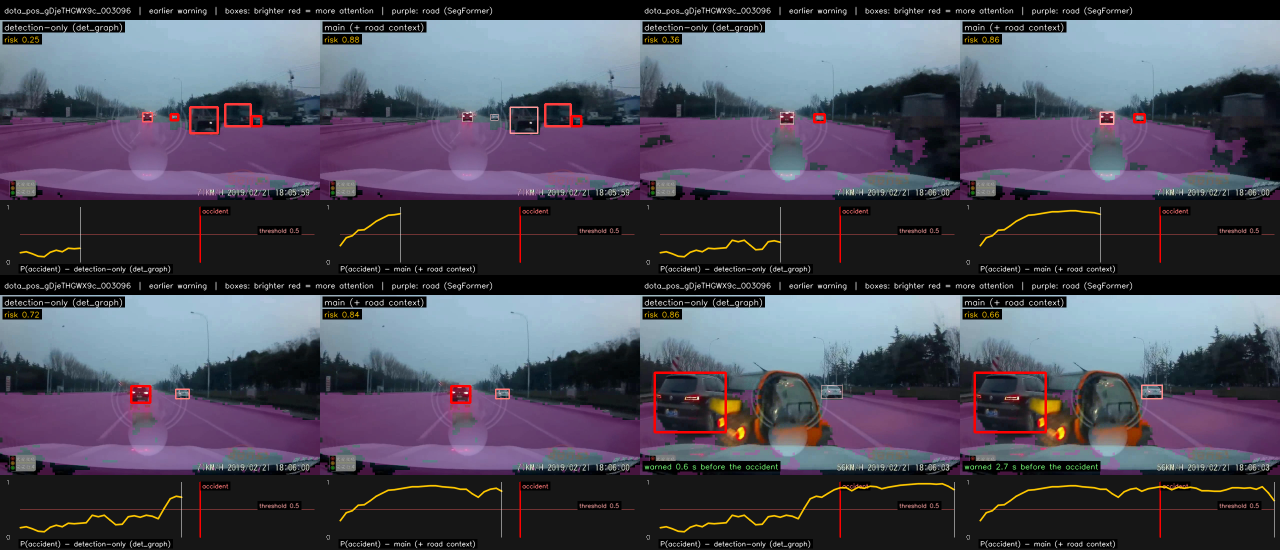

In [13]:
show_case("earlier_warning_dota_pos_gDjeTHGWX9c", "Earlier warning, DoTA clip gDjeTHGWX9c_003096", "Same pattern: the main model alarms about 2 s before the baseline does.")

#### 5.3 False alarm

### False alarm, CCD normal clip 001246
`false_alarm_ccd_neg_001246`  
**main model:** FALSE ALARM at 4.4 s  
**detection-only baseline:** no alarm (correct: no accident)  
No accident happens here, but the main model raises an alarm; the baseline correctly stays quiet.

*Storyboard (same clip, stills):*

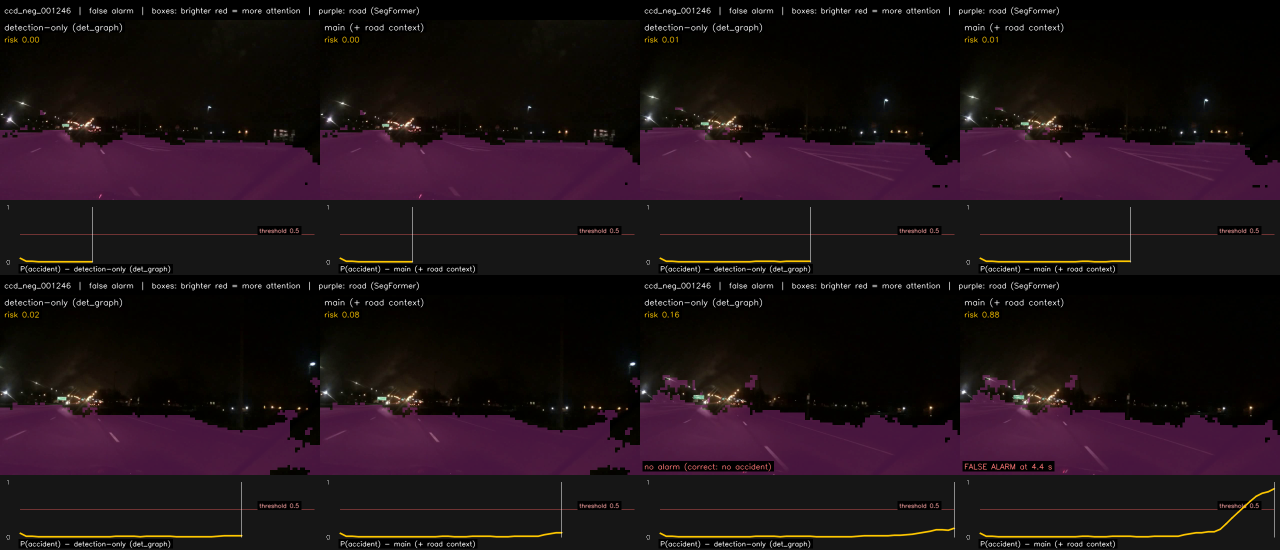

In [14]:
show_case("false_alarm", "False alarm, CCD normal clip 001246", "No accident happens here, but the main model raises an alarm; the baseline correctly stays quiet.")

#### 5.4 Miss

### Miss, CCD crash clip 000397
`miss_ccd_pos_000397`  
**main model:** no warning before the accident  
**detection-only baseline:** warned 1.1 s before the accident  
The accident happens, but the main model never alarms before it; the baseline warns 1.1 s ahead.

*Storyboard (same clip, stills):*

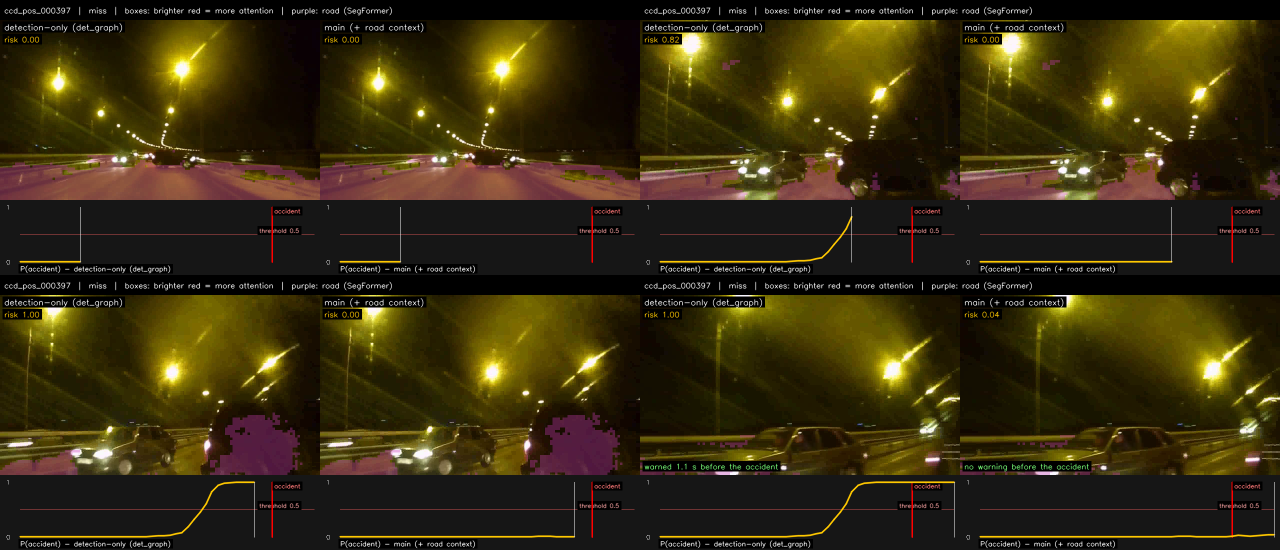

In [15]:
show_case("miss", "Miss, CCD crash clip 000397", "The accident happens, but the main model never alarms before it; the baseline warns 1.1 s ahead.")

## 6. Results
All numbers are produced by the Kaggle runs (`results/README.md`) and aggregated by `src/analysis/report.py`; values are **mean ± std over 3 seeds** (each seed is already averaged over the 5 folds).
### 6.1 Baselines and main model on the comparable protocols (CCD official split, DoTA STAGNet folds)

In [16]:
display(Markdown(open(os.path.join(TAB, "main_comparable.md")).read()))

| model      | ccd_official AP   | ccd_official mTTA   | ccd_official TTA_R80   | dota_stagnet AP   | dota_stagnet mTTA   | dota_stagnet TTA_R80   |
|:-----------|:------------------|:--------------------|:-----------------------|:------------------|:--------------------|:-----------------------|
| frame_lstm | 1.000 Â± 0.000     | 4.82 Â± 0.16         | 4.59 Â± 0.39            | 0.722 Â± 0.021     | 3.84 Â± 0.07         | 4.59 Â± 0.08            |
| det_lstm   | 1.000 Â± 0.000     | 4.59 Â± 0.14         | 4.23 Â± 0.17            | 0.798 Â± 0.005     | 3.49 Â± 0.15         | 4.18 Â± 0.07            |
| det_graph  | 1.000 Â± 0.000     | 4.61 Â± 0.10         | 4.29 Â± 0.18            | 0.808 Â± 0.004     | 3.55 Â± 0.07         | 4.13 Â± 0.12            |
| main       | 1.000 Â± 0.000     | 4.58 Â± 0.23         | 4.19 Â± 0.30            | 0.803 Â± 0.007     | 3.64 Â± 0.15         | 4.21 Â± 0.13            |

### 6.2 Clean (source-grouped) splits with ablations
`not run` = ablations were run on DoTA only, because CCD is saturated (see 6.6).

In [17]:
display(Markdown(open(os.path.join(TAB, "main_and_ablations_clean.md")).read()))

| model               | ccd_source AP   | ccd_source mTTA   | ccd_source TTA_R80   | dota_source AP   | dota_source mTTA   | dota_source TTA_R80   |
|:--------------------|:----------------|:------------------|:---------------------|:-----------------|:-------------------|:----------------------|
| frame_lstm          | 1.000 Â± 0.000   | 4.67 Â± 0.05       | 4.37 Â± 0.08          | 0.722 Â± 0.016    | 3.59 Â± 0.06        | 4.42 Â± 0.14           |
| det_lstm            | 0.996 Â± 0.006   | 4.63 Â± 0.02       | 4.32 Â± 0.04          | 0.800 Â± 0.014    | 3.47 Â± 0.14        | 4.10 Â± 0.11           |
| det_graph           | 0.999 Â± 0.000   | 4.62 Â± 0.13       | 4.25 Â± 0.20          | 0.814 Â± 0.017    | 3.62 Â± 0.15        | 4.00 Â± 0.05           |
| main                | 1.000 Â± 0.000   | 4.61 Â± 0.08       | 4.21 Â± 0.16          | 0.821 Â± 0.012    | 3.47 Â± 0.09        | 4.02 Â± 0.09           |
| main_no_interaction | 1.000 Â± 0.000   | 4.68 Â± 0.01       | 4.43 Â± 0.07          | 0.806 Â± 0.007    | 3.38 Â± 0.05        | 4.04 Â± 0.01           |
| main_no_app         | 1.000 Â± 0.000   | 4.52 Â± 0.08       | 4.06 Â± 0.18          | 0.809 Â± 0.010    | 3.34 Â± 0.02        | 3.93 Â± 0.02           |
| main_no_geo         | 0.999 Â± 0.000   | 4.61 Â± 0.10       | 4.21 Â± 0.17          | 0.741 Â± 0.013    | 3.57 Â± 0.08        | 4.29 Â± 0.14           |
| main_no_frame       | 0.989 Â± 0.001   | 4.63 Â± 0.03       | 4.01 Â± 0.00          | 0.794 Â± 0.009    | 3.38 Â± 0.06        | 4.08 Â± 0.07           |
| main_gru            | 1.000 Â± 0.000   | 4.63 Â± 0.00       | 4.30 Â± 0.00          | 0.820 Â± 0.010    | 3.45 Â± 0.14        | 3.91 Â± 0.12           |
| geo_only            | not run         | not run           | not run              | 0.814 Â± 0.002    | 3.35 Â± 0.05        | 4.00 Â± 0.03           |
| geo_seg             | not run         | not run           | not run              | 0.809 Â± 0.010    | 3.34 Â± 0.02        | 3.93 Â± 0.02           |

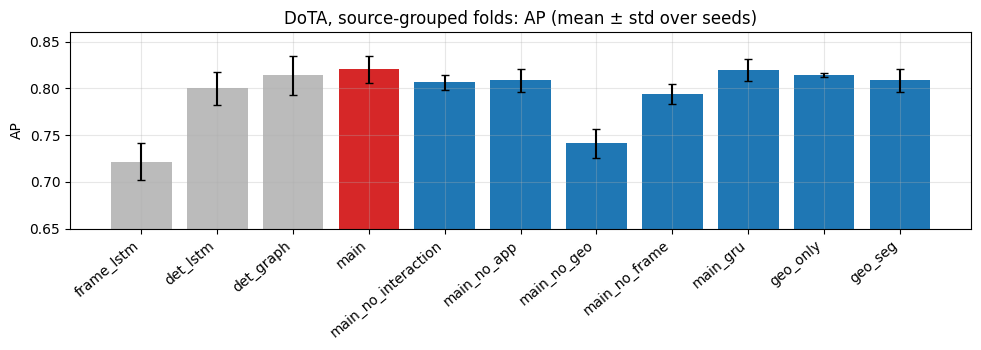

In [18]:
runs = pd.read_csv(os.path.join(TAB, "runs_raw.csv"))
d = runs[runs.scheme == "dota_source"].groupby(["exp", "seed"]).AP.mean().groupby("exp").agg(["mean", "std"])
order = ["frame_lstm", "det_lstm", "det_graph", "main", "main_no_interaction", "main_no_app", "main_no_geo", "main_no_frame", "main_gru", "geo_only", "geo_seg"]
d = d.loc[order]
fig, ax = plt.subplots(figsize=(10, 3.6))
cols = ["#bbb" if n in order[:3] else ("#d62728" if n == "main" else "#1f77b4") for n in d.index]
ax.bar(d.index, d["mean"], yerr=d["std"], color=cols, capsize=3)
ax.set_ylim(0.65, 0.86); ax.set_ylabel("AP"); ax.set_title("DoTA, source-grouped folds: AP (mean ± std over seeds)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

### 6.3 Threshold sweep
Lead time (seconds before the accident) and precision/recall as the alarm threshold moves, for the four main models on all four split schemes.

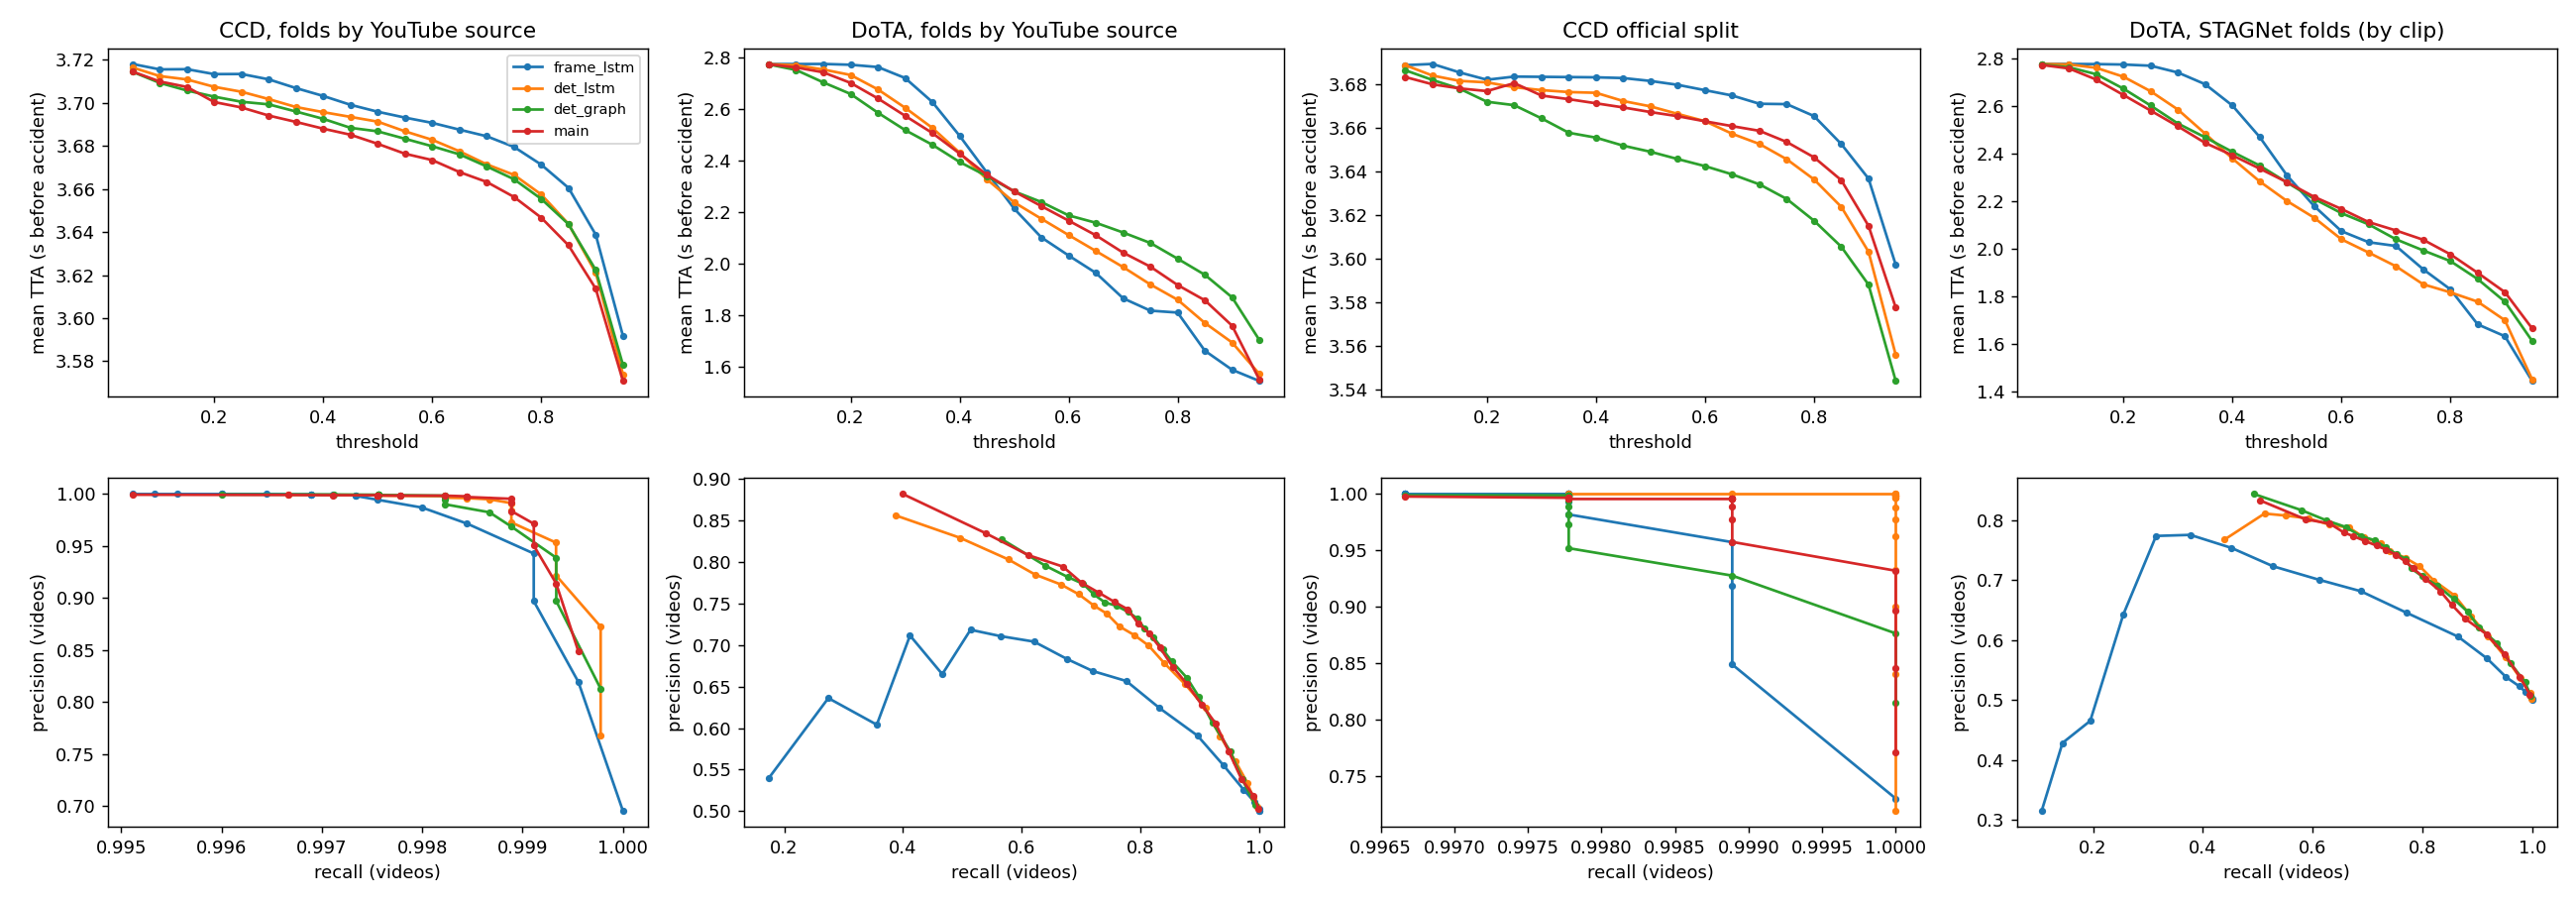

In [19]:
display(Image(os.path.join(RES, "figures/threshold_sweep.png"), width=1200))

### 6.4 Early versus late warnings: `main` vs `det_graph`
Share of accident videos, alarm at P ≥ 0.5, differences up to 0.1 s count as the same time (mean (std) over seeds).

,main earlier,baseline earlier,same time,only main warns,only baseline warns,both miss
scheme,,,,,,
ccd_source,0.026 (0.013),0.028 (0.021),0.943 (0.009),0.001 (0.001),0.001 (0.000),0.001 (0.001)
dota_source,0.254 (0.055),0.209 (0.044),0.281 (0.033),0.071 (0.006),0.062 (0.009),0.123 (0.025)


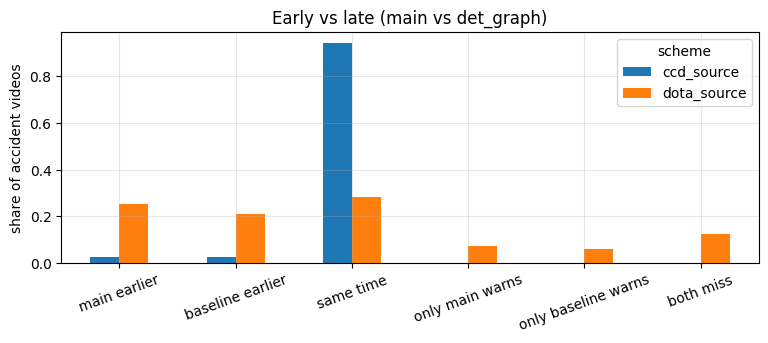

In [20]:
el = pd.read_csv(os.path.join(TAB, "early_late_summary.csv")).set_index("scheme")
cats = ["main earlier", "baseline earlier", "same time", "only main warns", "only baseline warns", "both miss"]
show = pd.DataFrame({c: [f"{el.loc[s, c + ' (mean)']:.3f} ({el.loc[s, c + ' (std)']:.3f})" for s in el.index] for c in cats}, index=el.index)
display(show)
el_m = pd.DataFrame({c: el[c + " (mean)"] for c in cats})
el_m.T.plot.bar(figsize=(9, 3), color=["C0", "C1"]); plt.ylabel("share of accident videos"); plt.title("Early vs late (main vs det_graph)"); plt.xticks(rotation=20); plt.show()

### 6.5 Failure analysis (main model, threshold 0.5)

In [21]:
for s in ("dota_source", "ccd_source"):
    e = pd.read_csv(os.path.join(TAB, f"errors_{s}.csv"))
    display(Markdown(f"**{s}**")); display(e.round(3).set_index(["y", "kind"]))

**dota_source**

mean    std
y kind                           
0 correct rejection  0.663  0.043
  false alarm        0.337  0.043
1 late (< 0.5 s)     0.034  0.009
  miss               0.185  0.034
  timely             0.781  0.042

**ccd_source**

mean    std
y kind                           
0 correct rejection  0.999  0.001
  false alarm        0.001  0.001
1 late (< 0.5 s)     0.001    NaN
  miss               0.002  0.001
  timely             0.998  0.000

### 6.6 Benchmark audit
Three checks on the datasets themselves, which change how the numbers above should be read.

**(a) Source leakage:** test videos sharing a YouTube source with training videos.

In [22]:
rows = []
for ds in ("ccd", "dota"):
    for k, v in json.load(open(os.path.join(TAB, f"leakage_{ds}.json"))).items():
        rows.append(dict(split=k, test_videos=sum(v["test_videos"]), sharing_with_train=sum(v["shared"])))
lk = pd.DataFrame(rows); lk["share"] = (lk.sharing_with_train / lk.test_videos).round(3); display(lk.set_index("split"))

,test_videos,sharing_with_train,share
split,,,
ccd_official / shared source,900,299,0.332
ccd_source / shared source,4500,0,0.000
dota_stagnet / shared clip,1490,0,0.000
dota_stagnet / shared source,1490,1476,0.991
dota_source / shared clip,1490,0,0.000
dota_source / shared source,1490,0,0.000


**(b) Shortcut probe:** logistic regression on simple inputs, ROC-AUC on held-out folds. A high score from the first frame alone means the label is readable without watching the accident develop.

In [23]:
sp = pd.read_csv(os.path.join(TAB, "shortcut_probe.csv")); display(sp.set_index(["dataset", "probe"]))

roc_auc  videos  positives  min_toa_frames
dataset probe                                                        
ccd     first_frame_emb     1.0000    4500       1500              30
        first10_frame_emb   1.0000    4500       1500              30
        n_objects_first10   0.6263    4500       1500              30
dota    first_frame_emb     0.8090    1490        745               1
        first10_frame_emb   0.8107    1490        745               1
        n_objects_first10   0.5451    1490        745               1

**(c) Cross-dataset transfer** (train on one dataset, test on the other; DoTA is balanced, so AP 0.5 is chance):

In [24]:
display(Markdown(open(os.path.join(TAB, "cross_dataset.md")).read()))

| model      | cross_ccd2dota AP   | cross_ccd2dota mTTA   | cross_ccd2dota TTA_R80   | cross_dota2ccd AP   | cross_dota2ccd mTTA   | cross_dota2ccd TTA_R80   |
|:-----------|:--------------------|:----------------------|:-------------------------|:--------------------|:----------------------|:-------------------------|
| frame_lstm | 0.501 Â± 0.000       | 4.87 Â± 0.07           | 4.51 Â± 0.16              | 0.735 Â± 0.127       | 4.20 Â± 0.30           | 4.50 Â± 0.58              |
| det_lstm   | 0.505 Â± 0.003       | 4.79 Â± 0.04           | 4.14 Â± 0.19              | 0.722 Â± 0.039       | 4.15 Â± 0.09           | 3.91 Â± 0.16              |
| det_graph  | 0.509 Â± 0.003       | 4.80 Â± 0.06           | 4.24 Â± 0.16              | 0.694 Â± 0.046       | 4.21 Â± 0.15           | 4.33 Â± 0.18              |
| main       | 0.514 Â± 0.010       | 4.78 Â± 0.05           | 4.35 Â± 0.08              | 0.719 Â± 0.091       | 4.13 Â± 0.10           | 4.23 Â± 0.11              |